####  Concept Exercise: Crop Yield Prediction using Polynomial Regression (Starter Notebook)

Welcome to the concept exercise for **Submodule 02: Polynomial & Non-Linear Regression**!

In this exercise, you will model the non-linear relationship between **Fertilizer Application (kg/hectare)** and **Crop Yield (Tons/hectare)**.

---

###  Objectives:
1. Load and explore a non-linear agricultural dataset.
2. Observe why simple linear regression fails to capture optimal fertilizer saturation points.
3. Build a Scikit-Learn `Pipeline` combining `PolynomialFeatures(degree=2)` and `LinearRegression`.
4. Calculate and compare evaluation metrics (**RMSE**, **$R^2$**) between linear and polynomial models.
5. Identify the exact **Optimal Fertilizer Level** that yields maximum crop output.

---

###  Instructions:
* Follow the step-by-step TODO prompts below.
* Fill in the missing code sections marked with `# TODO: ...`.

In [1]:
# Dataset Generation & Setup
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

# Global styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Seed for reproducibility
np.random.seed(2026)
n_samples = 150

# Synthetic Agricultural Dataset: Fertilizer (kg/ha) vs Crop Yield (Tons/ha)
fertilizer = np.random.uniform(20, 250, size=n_samples)

# True physical curve: Yield increases up to ~140 kg/ha, then drops due to chemical toxicity
true_yield = 2.0 + 0.08 * fertilizer - 0.00028 * (fertilizer**2)
observed_yield = true_yield + np.random.normal(0, 0.8, size=n_samples)

df_crop = (
    pd.DataFrame(
        {
            "fertilizer_kg_ha": fertilizer.round(1),
            "crop_yield_tons": observed_yield.round(2),
        }
    )
    .sort_values(by="fertilizer_kg_ha")
    .reset_index(drop=True)
)

print("--- Agricultural Crop Yield Dataset Preview ---")
print(df_crop.head())

--- Agricultural Crop Yield Dataset Preview ---
   fertilizer_kg_ha  crop_yield_tons
0              20.6             4.91
1              25.3             3.69
2              27.0             3.49
3              30.8             4.69
4              31.1             5.25


---
## Task 1: Train-Test Split

1. Define feature matrix `X` using `fertilizer_kg_ha`.
2. Define target vector `y` using `crop_yield_tons`.
3. Perform an 80/20 train-test split using `train_test_split(random_state=42)`.

In [2]:
# TODO: Train-Test Split
# TODO: Define X and y
X = df_crop[["fertilizer_kg_ha"]].values
y = df_crop["crop_yield_tons"].values

# TODO: Split into 80% train and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape : {X_test.shape}")

Training set shape: (120, 1)
Testing set shape : (30, 1)


---
## Task 2: Baseline Linear Model (Degree 1)

1. Instantiate and fit a standard `LinearRegression` model on `(X_train, y_train)`.
2. Predict on `X_test`.
3. Compute baseline **RMSE** and **$R^2$**.

In [4]:
# TODO: Baseline Linear Model
# TODO: Fit simple Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# TODO: Predict on test set
y_pred_linear = linear_model.predict(X_test)

# TODO: Calculate metrics
rmse_linear = root_mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test,y_pred_linear)

print("--- Baseline Linear Model Performance ---")
print(f"Linear RMSE: {rmse_linear}")
print(f"Linear R²  : {r2_linear}")

--- Baseline Linear Model Performance ---
Linear RMSE: 1.519184365806733
Linear R²  : -0.03773634629905853


---
## Task 3: Polynomial Model (Degree 2) via Scikit-Learn Pipeline

1. Build a pipeline using `make_pipeline()` combining `PolynomialFeatures(degree=2)` and `LinearRegression()`.
2. Fit the pipeline strictly on `(X_train, y_train)`.
3. Predict on `X_test`.
4. Calculate **RMSE** and **$R^2$**.

In [5]:
# TODO: Polynomial Model
# TODO: Create and fit Degree-2 Polynomial Pipeline
poly_model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly_model.fit(X_train, y_train)

# TODO: Predict on test set
y_pred_poly = poly_model.predict(X_test)

# TODO: Calculate metrics
rmse_poly = root_mean_squared_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print("--- Polynomial Model (Degree 2) Performance ---")
print(f"Polynomial RMSE: {rmse_poly}")
print(f"Polynomial R²  : {r2_poly}")

--- Polynomial Model (Degree 2) Performance ---
Polynomial RMSE: 0.8552913018399317
Polynomial R²  : 0.6710770520072753


---
## Task 4: Visualization & Curve Comparison

Plot the raw test data points along with the predicted curves for both the **Linear Model** and the **Polynomial Model** across a smooth range of fertilizer values from 20 to 250.

d:\Machine_Learning(cdac)\my_practise\cdacvenv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
d:\Machine_Learning(cdac)\my_practise\cdacvenv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


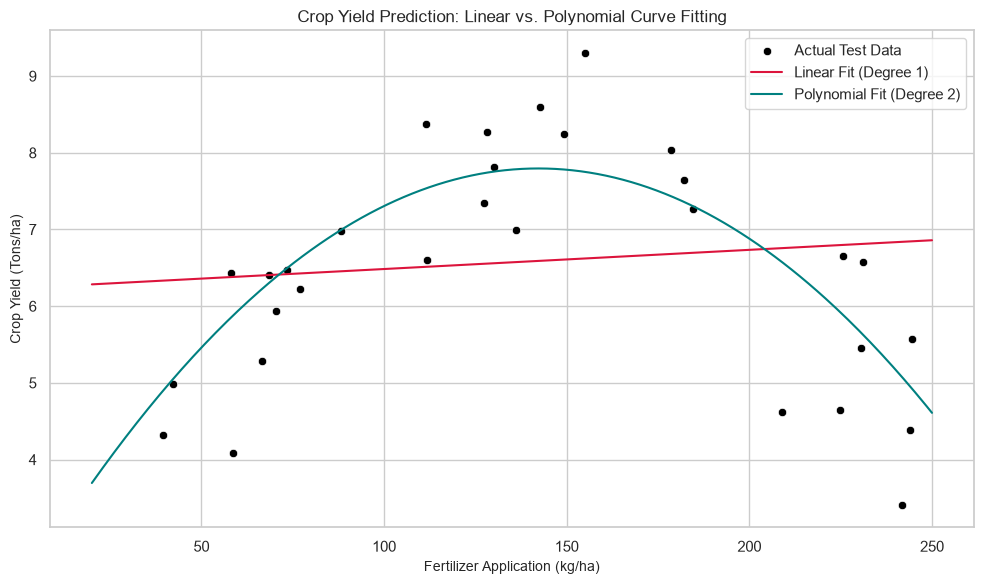

In [7]:
# TODO: Plotting Comparison
# Smooth domain for curve plotting
X_plot = pd.DataFrame({"fertilizer_kg_ha": np.linspace(20, 250, 300)})

# TODO: Generate smooth predictions for both models
y_plot_linear = linear_model.predict(X_plot)
y_plot_poly = poly_model.predict(X_plot)

plt.figure(figsize=(10, 6))

# TODO: Plot test scatter points and fitted curves
sns.scatterplot(
    x=X_test[:, 0],
    y=y_test,
    color='black',
    label='Actual Test Data'
)
plt.plot(X_plot['fertilizer_kg_ha'], y_plot_linear, color='crimson', label='Linear Fit (Degree 1)')
plt.plot(X_plot['fertilizer_kg_ha'], y_plot_poly, color='teal', label='Polynomial Fit (Degree 2)')

plt.title(
    "Crop Yield Prediction: Linear vs. Polynomial Curve Fitting", fontsize=12
)
plt.xlabel("Fertilizer Application (kg/ha)", fontsize=10)
plt.ylabel("Crop Yield (Tons/ha)", fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

---
## Task 5: Find Optimal Fertilizer Dosage

Using the fitted polynomial model, calculate the fertilizer dosage ($\text{kg/ha}$) that yields the **maximum predicted crop output**.

*Hint: For quadratic $y = a x^2 + b x + c$, the peak occurs at $x = -\frac{b}{2a}$, or you can locate the maximum predicted value along `X_plot`.*

In [8]:
# TODO: Optimization Calculation
# TODO: Find optimal fertilizer dosage and corresponding maximum yield
max_idx = np.argmax(y_plot_poly)
opt_fertilizer = X_plot.iloc[max_idx]['fertilizer_kg_ha']
max_predicted_yield = y_plot_poly[max_idx]

print(f"Optimal Fertilizer Dosage : {opt_fertilizer:.2f} kg/ha")
print(f"Maximum Estimated Yield   : {max_predicted_yield:.2f} Tons/ha")

Optimal Fertilizer Dosage : 142.31 kg/ha
Maximum Estimated Yield   : 7.80 Tons/ha
